# The Impact of Social Media on Students: Data Analysis & Classification


## 1. Introduction

Social media is now part of students' daily lives. While it helps them communicate and learn, many people worry that heavy use
may hurt their sleep, increase stress, and lower their academic performance. This project explores these concerns using a dataset on social media use among students.

### Objectives
The goal of this analysis is to understand how social media use is related to students' academic performance and well-being outcomes. Spesifically, it asks:

1. Is daily usage duration related to Academic_Performance_GPA, Sleep_Quality_Score and Perceived_Stress_Score?
2. Is the platform students use most often related to the Overall_Impact they report (beneficial, neutral or negative)?
3. Do sleep and stress help explain the ralationship between usage and Academic_Performance_GPA?
4. Can Overall_Impact be predicted from usage, sleep, stress, GPA and platform?

### Dataset
The dataset is 'Social_media_impact_on_life' by Harish Yadav comes from Kaggle Learn and contains 4500 students. It included demographic information, daily usage hours, most-used platform, sleep hours, stress-level, GPA and overall impact.

### Metodology
The analysis follows these steps: data cleaning, exploratory data analysis, Spearman correlation, group comparison by usage level, a chi-square test for platform and overall impact, OLS regresion to test the role of sleep and stress, and classification models(Logistic Regression and Random Forest).

### Note
This analysis shows associations, not causation. The dataset may also be synthetic or self-reported, so the findings should be read as patterns in this data, not as proof about all students.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn import linear_model
df = pd.read_csv('Social_media_impact_on_life.csv')

## 2. Data Cleaning

In [2]:
df.shape

(4500, 16)

In [3]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Index          

In [5]:
df.describe()

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64

In [8]:
#Fill the null values in two columns (fill the missing value with the median)
df['Perceived_Stress_Score']=df['Perceived_Stress_Score'].fillna(df['Perceived_Stress_Score'].median())

In [9]:
#because the target is GPA and there are null value, I choose those drop them.
df = df.dropna()

In [10]:
# Category concistency check
category_columns = ['Gender','Academic_Level','Primary_Platform','Device_Type','Late_Night_Usage',
                    'Social_Comparison_Frequency','Overall_Impact']
for col in category_columns:
    print(df[col].value_counts(dropna=False))

Gender
Female               2196
Male                 2007
Non-Binary            120
Prefer not to say      92
Name: count, dtype: int64
Academic_Level
Undergraduate    2721
High School      1450
Postgraduate      244
Name: count, dtype: int64
Primary_Platform
Instagram      1425
TikTok         1197
YouTube         803
Snapchat        465
Reddit          227
X (Twitter)     203
LinkedIn         95
Name: count, dtype: int64
Device_Type
Smartphone    3707
Laptop/PC      583
Tablet         125
Name: count, dtype: int64
Late_Night_Usage
True     2591
False    1824
Name: count, dtype: int64
Social_Comparison_Frequency
Sometimes     1562
Frequently    1224
Rarely         751
Always         619
Never          259
Name: count, dtype: int64
Overall_Impact
Beneficial    3610
Neutral        642
Negative       163
Name: count, dtype: int64


- 46 missing Perceived_Stress_Score values was filled with the median.
- 85 null value Academic_Performance_GPA was dropped because that is the target 
- category columns were checked, and the spelling was concistent, so no changes were needed.
- Data type were correct and no unreasonable values were found.
- No duplicated rows were found. 

## 3. Exploratory Data Analysis

## 3.1 Categorical features

In [11]:
category_columns = ['Gender','Academic_Level','Primary_Platform','Device_Type','Late_Night_Usage',
                    'Social_Comparison_Frequency','Overall_Impact']

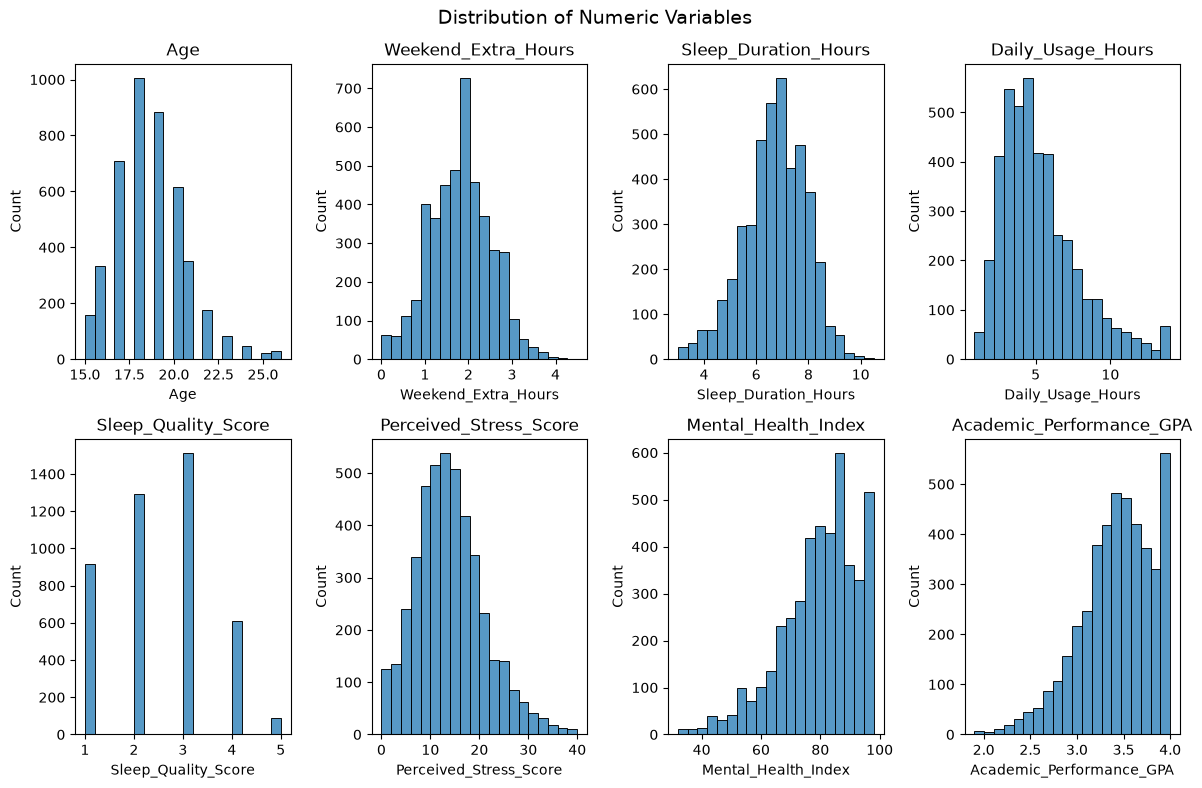

In [12]:
# Distribution of numerical variables
num_col = ['Age','Weekend_Extra_Hours','Sleep_Duration_Hours','Daily_Usage_Hours', 'Sleep_Quality_Score', 'Perceived_Stress_Score','Mental_Health_Index','Academic_Performance_GPA']
fig, axes = plt.subplots(2, 4, figsize=(12,8))

for ax, col in zip(axes.flatten(), num_col):
    sns.histplot(data=df, x=col, bins=20, ax=ax)
    ax.set_title(col)

fig.suptitle('Distribution of Numeric Variables', fontsize=14)
plt.tight_layout()
plt.show()    

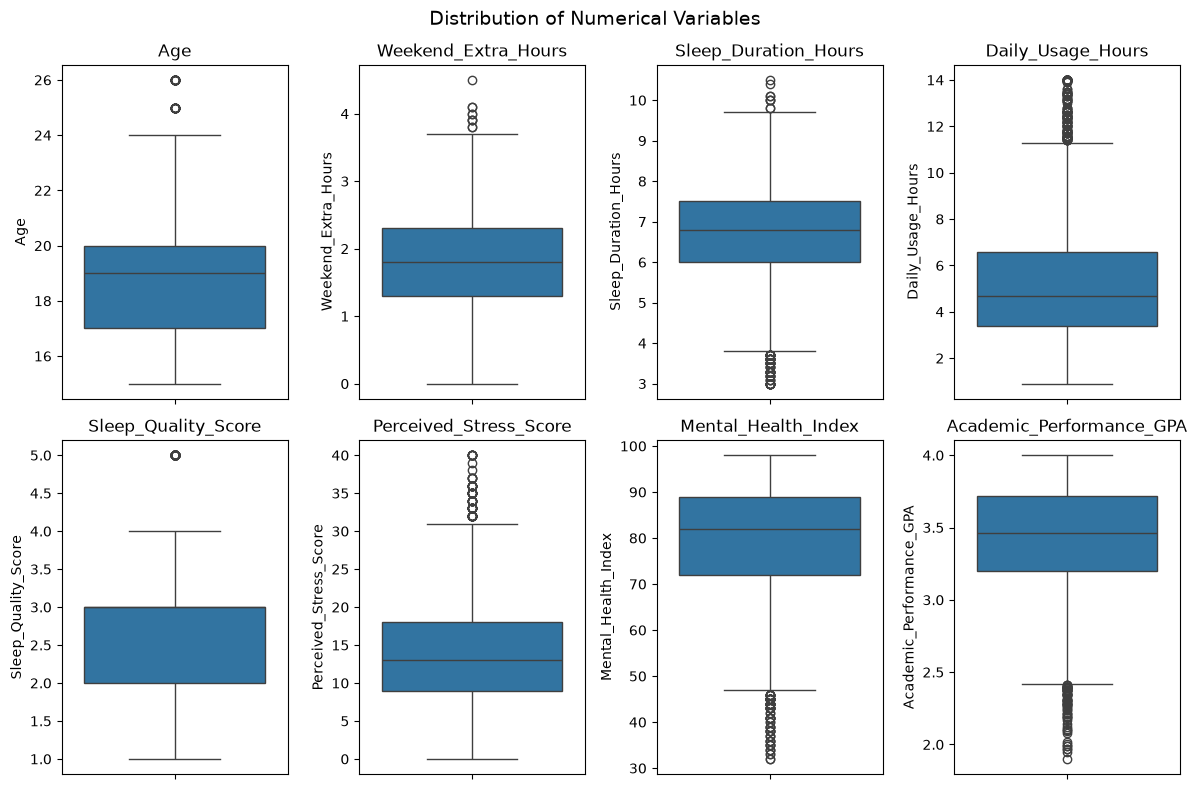

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(12,8))

for ax, col in zip(axes.flatten(), num_col):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(col)

fig.suptitle('Distribution of Numerical Variables', fontsize=14)
plt.tight_layout()
plt.show()    

In [14]:
result = []

for col in num_col:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3-Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR
    n_out = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    result.append({
        'Column' : col,
        'Q1': Q1,
        'Q3':Q3,
        'IQR':IQR,
        'Lower Bound':lower_bound,
        'Upper Bound':upper_bound,
        'Total Outlier':n_out,
        '% Outlier': round(n_out/len(df)*100,2)
    })

iqr_df = pd.DataFrame(result).round(2)
iqr_df

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Total Outlier,% Outlier
0,Age,17.0,20.00,3.00,12.50,24.50,51,1.16
1,Weekend_Extra_Hours,1.3,2.30,1.00,-0.20,3.80,10,0.23
2,Sleep_Duration_Hours,6.0,7.50,1.50,3.75,9.75,72,1.63
3,Daily_Usage_Hours,3.4,6.60,3.20,-1.40,11.40,160,3.62
4,Sleep_Quality_Score,2.0,3.00,1.00,0.50,4.50,90,2.04
5,Perceived_Stress_Score,9.0,18.00,9.00,-4.50,31.50,74,1.68
6,Mental_Health_Index,72.0,89.00,17.00,46.50,114.50,83,1.88
7,Academic_Performance_GPA,3.2,3.72,0.52,2.42,4.50,68,1.54


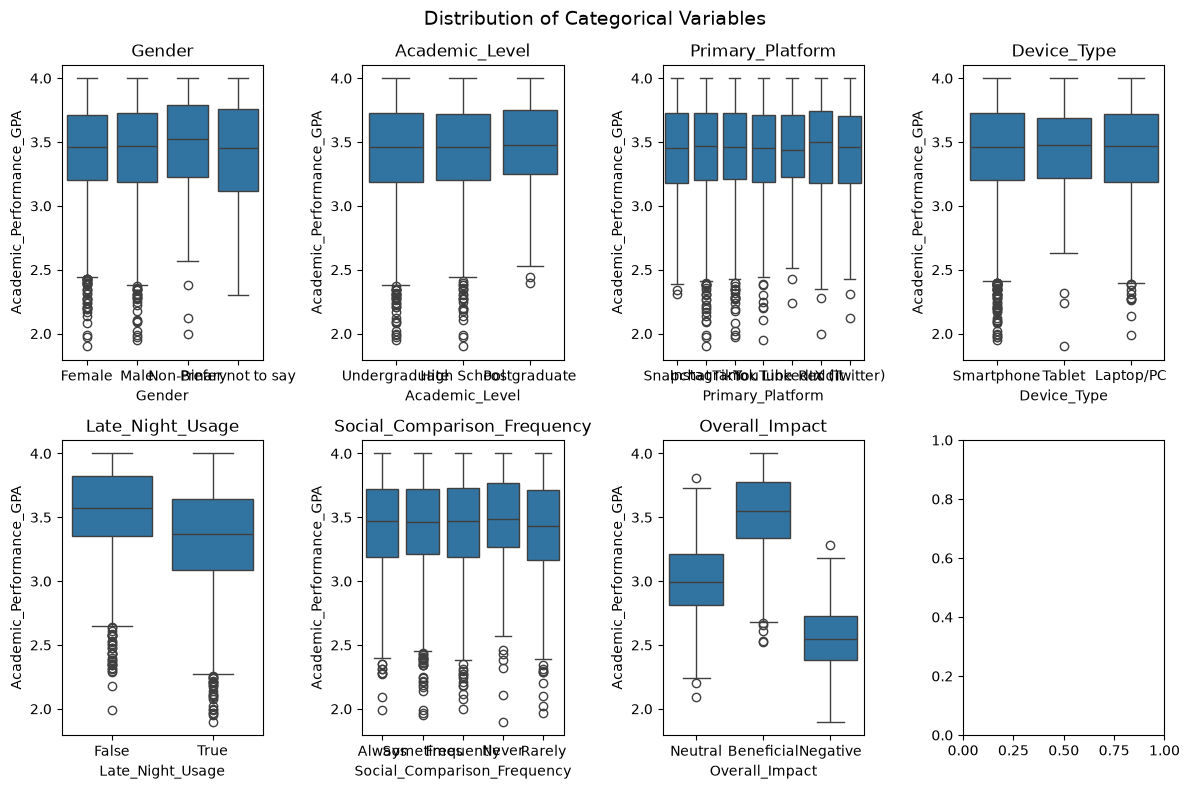

In [15]:
category_columns = ['Gender','Academic_Level','Primary_Platform','Device_Type','Late_Night_Usage',
                    'Social_Comparison_Frequency','Overall_Impact']
fig, axes = plt.subplots(2, 4, figsize=(12,8))

for ax, col in zip(axes.flatten(), category_columns):
    sns.boxplot(data=df, x=col, y='Academic_Performance_GPA', ax=ax)
    ax.set_title(col)

fig.suptitle('Distribution of Categorical Variables', fontsize=14)
plt.tight_layout()
plt.show()    

In [16]:
for col in category_columns:
    print(df.groupby(col)['Academic_Performance_GPA'].agg(['count','mean','median']).round(2), '\n')

                   count  mean  median
Gender                                
Female              2196  3.42    3.46
Male                2007  3.43    3.47
Non-Binary           120  3.47    3.52
Prefer not to say     92  3.42    3.45 

                count  mean  median
Academic_Level                     
High School      1450  3.43    3.46
Postgraduate      244  3.47    3.48
Undergraduate    2721  3.43    3.46 

                  count  mean  median
Primary_Platform                     
Instagram          1425  3.43    3.47
LinkedIn             95  3.43    3.44
Reddit              227  3.43    3.50
Snapchat            465  3.43    3.45
TikTok             1197  3.43    3.46
X (Twitter)         203  3.43    3.46
YouTube             803  3.42    3.45 

             count  mean  median
Device_Type                     
Laptop/PC      583  3.43    3.47
Smartphone    3707  3.43    3.46
Tablet         125  3.44    3.48 

                  count  mean  median
Late_Night_Usage                 

**To make sure the difference between mean and median is actual or by accident, we can evaluate the statistic, because GPA is pretty skewed, kruskal-Walis is safer than ANOVA**

In [17]:
from scipy.stats import kruskal

for col in ['Gender','Academic_Level','Primary_Platform','Device_Type',
            'Late_Night_Usage','Social_Comparison_Frequency']:
    groups = [g['Academic_Performance_GPA'].values for _, g in df.groupby(col)]
    stat, p = kruskal(*groups)
    print(f'{col}: p = {p:.4f}')

Gender: p = 0.3830
Academic_Level: p = 0.4178
Primary_Platform: p = 0.9794
Device_Type: p = 0.9610
Late_Night_Usage: p = 0.0000
Social_Comparison_Frequency: p = 0.2733


**All of those columns almost didn't sifnificat except Late_Night_Usage ( p < 0.005), so it have to be one of feature.**

In [18]:
df.groupby('Late_Night_Usage')['Daily_Usage_Hours'].mean()

Late_Night_Usage
False    4.268969
True     6.027750
Name: Daily_Usage_Hours, dtype: float64

In [19]:
#karena histogram hanya memberi gambaran kasar jadi perlu dihiutng julah siswa per jam pemakaian
df['Usage_Group'] = pd.cut(df['Daily_Usage_Hours'], bins=[0, 3, 5, 7, 9, 15], labels=['0-3',
    '3-5', '5-7', '7-9', '9+'])

counts=df['Usage_Group'].value_counts().sort_index()
percent = (df['Usage_Group'].value_counts(normalize=True).sort_index() * 100).round()

print(pd.DataFrame({'Studentes':counts, 'Percents(%)':percent}))

             Studentes  Percents(%)
Usage_Group                        
0-3                809         18.0
3-5               1651         37.0
5-7               1042         24.0
7-9                495         11.0
9+                 418          9.0


In [20]:
print(df.groupby(['Usage_Group','Late_Night_Usage'])['Academic_Performance_GPA'].agg(['count','mean']).round(2))
#based on the result = jam pemakaian harian adalah pndorong utama gpa bukn waktu pakaianya.

                              count  mean
Usage_Group Late_Night_Usage             
0-3         False               491  3.73
            True                318  3.71
3-5         False               981  3.58
            True                670  3.57
5-7         False               189  3.40
            True                853  3.35
7-9         False                76  3.20
            True                419  3.14
9+          False                87  2.79
            True                331  2.80


In [21]:
import statsmodels.formula.api as smf

df['Late_Night_Usage'] = df['Late_Night_Usage'].astype(int)
model = smf.ols('Academic_Performance_GPA ~ Daily_Usage_Hours + Late_Night_Usage', data=df).fit()
print(model.summary())

                               OLS Regression Results                               
Dep. Variable:     Academic_Performance_GPA   R-squared:                       0.505
Model:                                  OLS   Adj. R-squared:                  0.504
Method:                       Least Squares   F-statistic:                     2247.
Date:                      Fri, 16 Oct 2026   Prob (F-statistic):               0.00
Time:                              03:22:08   Log-Likelihood:                -586.60
No. Observations:                      4415   AIC:                             1179.
Df Residuals:                          4412   BIC:                             1198.
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------

sns.countplot(data=df, x='Usage_Group', order=['0-3', '3-5', '5-7', '7-9', '9+'])
plt.title('Number of Student by Daily Usage Group', fontsize=14)
plt.tight_layout()
plt.show()

In [22]:
model2 = smf.ols('Academic_Performance_GPA ~ Daily_Usage_Hours + I(Daily_Usage_Hours**2) + Late_Night_Usage', data=df).fit()
print(f'{model2.rsquared}, {model2.rsquared_adj}')
print(model2.summary())

0.5047489951482123, 0.504412166081208
                               OLS Regression Results                               
Dep. Variable:     Academic_Performance_GPA   R-squared:                       0.505
Model:                                  OLS   Adj. R-squared:                  0.504
Method:                       Least Squares   F-statistic:                     1499.
Date:                      Fri, 16 Oct 2026   Prob (F-statistic):               0.00
Time:                              03:22:08   Log-Likelihood:                -585.75
No. Observations:                      4415   AIC:                             1180.
Df Residuals:                          4411   BIC:                             1205.
Df Model:                                 3                                         
Covariance Type:                  nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
------------------

**Daily usage hours is the dominant predictor of GPA (about -0.01 GPA per additional hour, R² ≈ 0.50). the relationship is approximately linear, and late night usage adds negligible explanatory power once total usage is accounted for. **

**Findings:** Most students  use social media for 3 to 5 hours per day (about 37%), followed by 5 to 7 hours (24%). Around 44% use it for more than 5 hours, and about 9% us it for 9 hours. Only 18% use it for less than 3 hours.

order=['0-3', '3-5', '5-7', '7-9', '9+']

fig1, axes = plt.subplots(1, 3, figsize=(16,5))

for ax, col in zip(axes, cols):
    sns.boxplot(data=df, x='Usage_Group', y=col, order=order, ax=ax)
    ax.set_title(f'{col} by Daily Usage Group')

fig1.suptitle('Outcomes by Daily Usage Group', fontsize=14)
plt.tight_layout()
plt.show()    

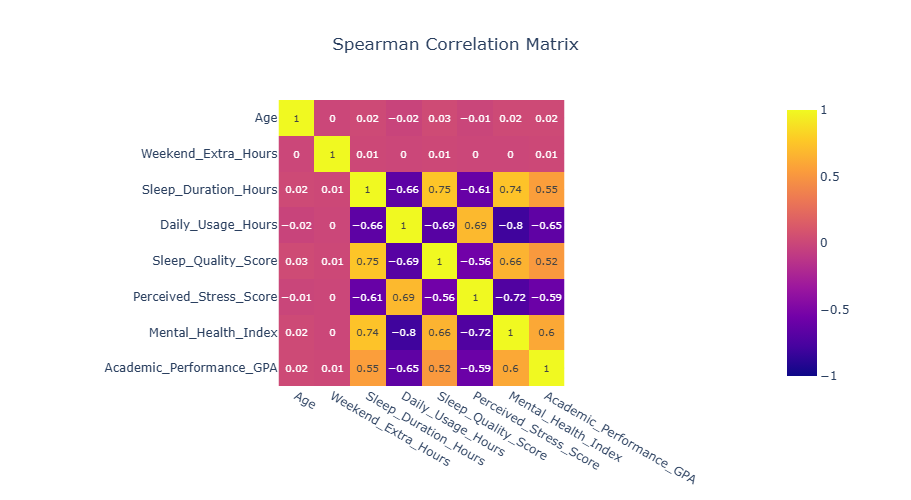

In [23]:
correlation = df[num_col].corr(method='spearman').round(2)

corr_fig=px.imshow(correlation, text_auto=True, title='Spearman Correlation Matrix', zmin=-1, zmax=1)
corr_fig.update_layout(width=700, height=500, title='Spearman Correlation Matrix', template='plotly_white', title_x=0.5)
corr_fig.show()

In [24]:
# VIF
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

feat = ['Daily_Usage_Hours', 'Sleep_Duration_Hours','Sleep_Quality_Score', 'Perceived_Stress_Score','Mental_Health_Index'] #independent variable
Xv = sm.add_constant(df[feat].dropna())

vif= pd.DataFrame({
    'Feature': Xv.columns,
    'VIF': [variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])]
})
print(vif[vif['Feature'] != 'const'])

                  Feature       VIF
1       Daily_Usage_Hours  4.249535
2    Sleep_Duration_Hours  3.348838
3     Sleep_Quality_Score  2.522431
4  Perceived_Stress_Score  2.702059
5     Mental_Health_Index  4.982835


In [25]:
# Perbandingan dua model (untuk menguji hipotesis)
# Model_1
model = smf.ols('Academic_Performance_GPA ~ Daily_Usage_Hours + Late_Night_Usage', data=df).fit()
#Model_2
model2 = smf.ols('Academic_Performance_GPA ~ Daily_Usage_Hours  + Late_Night_Usage + Sleep_Quality_Score + Perceived_Stress_Score',
                 data=df).fit()

print('Usage coef - Model 1:', round(model.params['Daily_Usage_Hours'], 3))
print('Usage coef - Model 2:', round(model2.params['Daily_Usage_Hours'], 3))
print('R2 - Model 1:', model.rsquared, '| Model 2:', model2.rsquared, )

Usage coef - Model 1: -0.106
Usage coef - Model 2: -0.072
R2 - Model 1: 0.5045583678417263 | Model 2: 0.5362828025117545


**Findings:** Daily usage (tpgether with late night usage) is associated with GPA (coef = -0.106 per hour, R² = 0.505). After adding sleep quality and stress, the usage coefficient decreases by about 3% (-0.072), but remains clearly negative. Sleep and perceived stress add only about 3 percentage points of explained variance (R² = 0.536). This suggests that sleep and stress accountfor part, but not most, of the link between usage and GPA. These are associations, not causal effects.

In [26]:
from scipy.stats import zscore
x_col = ['Daily_Usage_Hours', 'Sleep_Quality_Score', 'Perceived_Stress_Score']
d = df[x_col + ['Academic_Performance_GPA']].dropna()

X_z = sm.add_constant(df[x_col].apply(zscore))
y_z = zscore(df['Academic_Performance_GPA'])

model_z = sm.OLS(y_z, X_z).fit()
print(model_z.params.round(3))
print('R²:', round(model_z.rsquared, 3))

const                     0.000
Daily_Usage_Hours        -0.480
Sleep_Quality_Score       0.056
Perceived_Stress_Score   -0.256
dtype: float64
R²: 0.536


**Findings:** Standardized coefficients show that daily usage has the strongest association with GPA (β = -0.480),
followed by perceived stress (β = -0.256). Sleep quality has a very small independent association (β = 0.056),
likely because it overlaps with usage and stress. These are associations, not causal effects.

In [27]:
from scipy.stats import chi2_contingency
import numpy as np

def chi_cramers(a,b):
    tab = pd.crosstab(df[a], df[b])
    chi2, p, dof, expected = chi2_contingency(tab)
    n = tab.values.sum()
    v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
    return p, v

p, v = chi_cramers('Late_Night_Usage', 'Usage_Group')
print(f"p-value= {p:.4f}, Cramer\'s V = {v:.3f}")

p-value= 0.0000, Cramer's V = 0.423


**Findings:** A chi-square test showed significant association between late night usage and daily usage group (Cramer's V = 0.423, p = 0.423).Late night use is far more common among students using social media more than 5 hours a day (about 80%), than among lightere users (about 40%), which is concistent with late night usage acting as a cofounder rather than an independent driver of GPA.

# 4.Classification Model

In [28]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [29]:
#1.Feature and Target
data = df.copy()
data['Late_Night_Usage'] = data['Late_Night_Usage'].astype(int)

X = data.drop(['Academic_Performance_GPA', 'Overall_Impact','Usage_Group','Student_ID'], axis=1, errors='ignore')
y= data['Academic_Performance_GPA']
gpa_bin = pd.qcut(y, q=5, duplicates='drop')


In [30]:
#2.Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=gpa_bin)

#3.Preprocessing
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

pre = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

models = {
    'Dummy (mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1, max_depth=8, min_samples_leaf=30),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

rows = []
for name, m in models.items():
    pipe = Pipeline([('pre',pre),('model',m)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2')
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2 test': r2_score(y_test, pred),
        'R2 CV mean': cv.mean(),
        'R2 train': pipe.score(X_train, y_train)
    })

result = pd.DataFrame(rows).round(3)
result

,Model,MAE,RMSE,R2 test,R2 CV mean,R2 train
0,Dummy (mean),0.317,0.400,-0.000,-0.004,0.000
1,Linear Regression,0.217,0.267,0.553,0.531,0.541
2,Random Forest,0.222,0.272,0.538,0.525,0.585
3,Gradient Boosting,0.221,0.272,0.538,0.521,0.594


In [31]:
#karena hasil linear regresi r2 train 1.000 sehingga dicek kkembali ternyata STudent ID punya 3 rb++ nilai unik, jd dibuang sebelum training
print(df.columns.tolist())
print(X_train.select_dtypes(exclude='number').nunique().sort_values(ascending=False))
#karena hasil linear regresi r2 train 1.000 sehingga dicek kkembali ternyata STudent ID punya 3 rb++ nilai unik, jd dibuang sebelum training
#di sel sebelum ini

['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type', 'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage', 'Social_Comparison_Frequency', 'Perceived_Stress_Score', 'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact', 'Usage_Group']
Primary_Platform               7
Social_Comparison_Frequency    5
Gender                         4
Academic_Level                 3
Device_Type                    3
dtype: int64


In [32]:
#crossvalidaton
from sklearn.model_selection import GridSearchCV, KFold
pipe = Pipeline([('pre', pre),
                ('reg', RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))])

param_grid = {
    'reg__max_depth': [4,6,8,None],
    'reg__min_samples_leaf': [5,10,20,30],
}

gs = GridSearchCV(pipe, param_grid, cv=KFold(5, shuffle=True, random_state=42), scoring='r2', n_jobs=-1)
gs.fit(X_train, y_train)
print('CV R2:', round(gs.best_score_,3))
print('Test R2:', round(gs.score(X_test, y_test), 3))
print(gs.best_params_)

CV R2: 0.526
Test R2: 0.539
{'reg__max_depth': 6, 'reg__min_samples_leaf': 30}


In [33]:
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline 
import matplotlib.pyplot as plt


Linear Regression
Daily_Usage_Hours              0.4142
Perceived_Stress_Score         0.1076
Sleep_Duration_Hours           0.0266
Mental_Health_Index            0.0015
Social_Comparison_Frequency    0.0012
Late_Night_Usage               0.0002
Age                            0.0001
Weekend_Extra_Hours            0.0001
Gender                         0.0000
Sleep_Quality_Score            0.0000
Academic_Level                -0.0000
Device_Type                   -0.0005
Primary_Platform              -0.0006
dtype: float64

Random Forest (tuned)
Daily_Usage_Hours              0.6651
Perceived_Stress_Score         0.0626
Sleep_Duration_Hours           0.0103
Mental_Health_Index            0.0068
Weekend_Extra_Hours            0.0006
Sleep_Quality_Score            0.0003
Gender                         0.0003
Academic_Level                 0.0001
Device_Type                    0.0000
Social_Comparison_Frequency   -0.0000
Age                           -0.0002
Primary_Platform              -

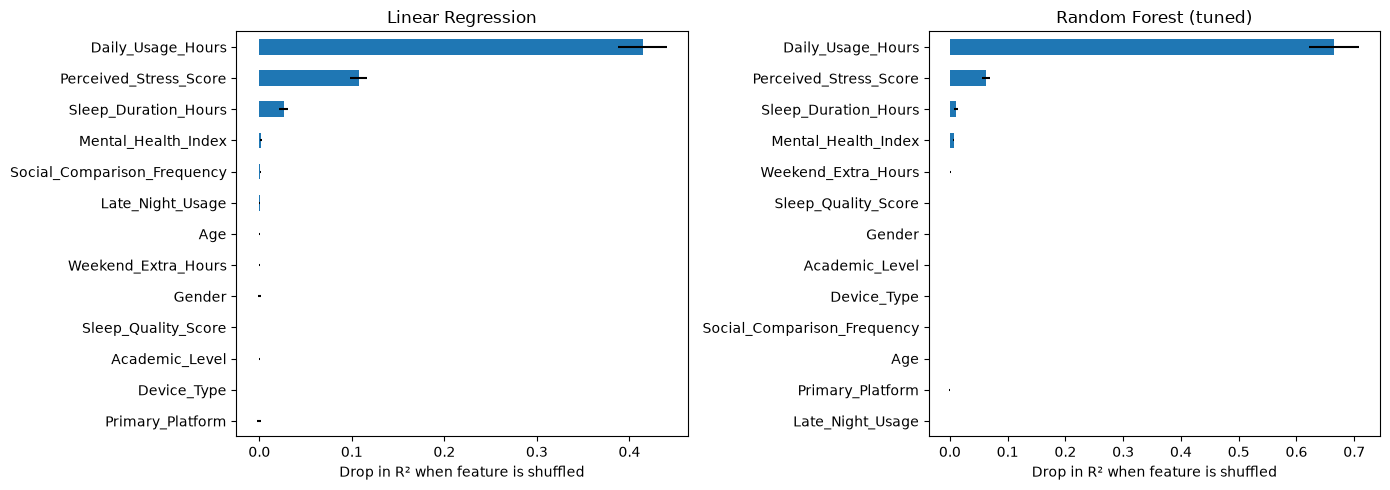

In [34]:
#first model: Linear Regression
lin =Pipeline([('pre',pre), ('reg', LinearRegression())]).fit(X_train, y_train)

#second : Random Forest
rf = gs.best_estimator_

fig, axes = plt.subplots(1,2, figsize=(14,5))
for ax, (name,model) in zip(axes, [('Linear Regression', lin), ('Random Forest (tuned)', rf)]):
    r = permutation_importance(model, X_test, y_test, n_repeats=20, random_state=42, scoring='r2', n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values()
    imp.plot.barh(ax=ax, xerr=pd.Series(r.importances_std, index=X_test.columns)[imp.index])
    ax.set_title(name)
    ax.set_xlabel('Drop in R² when feature is shuffled')
    print(f'\n{name}')
    print(imp.sort_values(ascending=False).round(4))

plt.tight_layout()
plt.show()

In [39]:
from sklearn.base import clone

cv = KFold(5, shuffle=True, random_state=42)
sets = {
    'All features': None,
    '3 features': ['Daily_Usage_Hours','Perceived_Stress_Score','Sleep_Duration_Hours'],
    'Usage only': ['Daily_Usage_Hours']
}

rows = []
for name, cols in sets.items():
    if cols is None:
        m = clone(lin); Xtr, Xte = X_train, X_test
    else:
        m = Pipeline([('sc', StandardScaler()), ('reg', LinearRegression())])
        Xtr, Xte = X_train[cols],X_test[cols]
    cvs = cross_val_score(m, Xtr, y_train, cv=cv, scoring='r2')
    m.fit(Xtr, y_train)
    rows.append({
        'Features': name, 'R2 CV': cvs.mean(), 
        'R2 test': m.score(Xte, y_test),
        'MAE test': mean_absolute_error(y_test, m.predict(Xte))
    })
pd.DataFrame(rows).round(3)

,Features,R2 CV,R2 test,MAE test
0,All features,0.531,0.553,0.217
1,3 features,0.534,0.556,0.217
2,Usage only,0.502,0.501,0.232


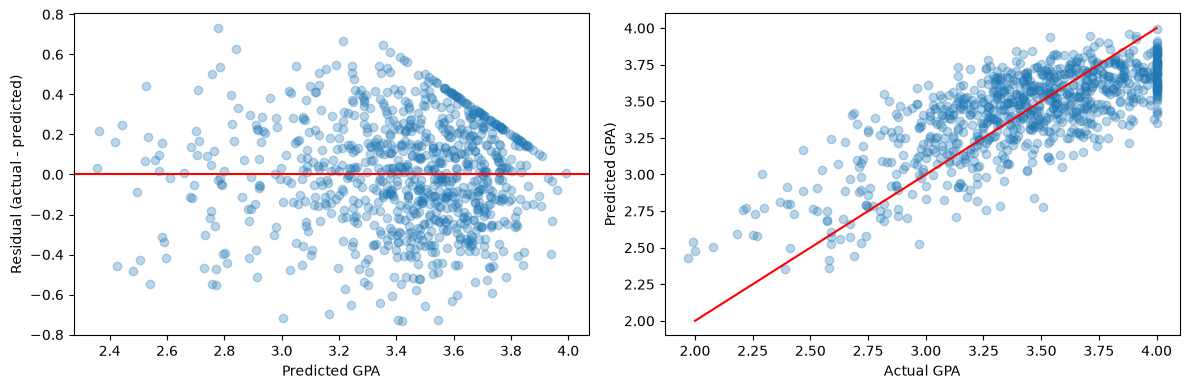

In [43]:
cols = ['Daily_Usage_Hours','Perceived_Stress_Score','Sleep_Duration_Hours']
final = Pipeline([('sc', StandardScaler()), ('reg', LinearRegression())])
final.fit(X_train[cols], y_train)
pred = final.predict(X_test[cols])
res = y_test - pred

fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].scatter(pred, res, alpha=0.3)
ax[0].axhline(0, color='red')
ax[0].set(xlabel='Predicted GPA', ylabel='Residual (actual - predicted)')
ax[1].scatter(y_test, pred, alpha=0.3)
ax[1].plot([2,4],[2,4], color='red')
ax[1].set(xlabel='Actual GPA', ylabel='Predicted GPA)')
plt.tight_layout()
plt.show()

In [44]:
d = pd.DataFrame({'actual': y_test, 'pred': pred})
d['resid'] = d['actual'] - d['pred']
d['band'] = pd.cut(d['actual'], bins=[1.9, 2.5, 3.0, 3.5, 3.9999, 4.0],
                  labels=['<2.5', '2.5-3.0', '3.0-3.5', '3.5-<4.0', '=4.0'])
print(d.groupby('band', observed=True)['resid'].agg(n='count', mean_resid='mean',
                                                   mae=lambda s:s.abs().mean()).round(3))
print('Share GPA == 4.0 :', round((y == 4.0).mean() * 100, 1), '%')

            n  mean_resid    mae
band                            
<2.5       21      -0.426  0.429
2.5-3.0   102      -0.212  0.269
3.0-3.5   351      -0.108  0.198
3.5-<4.0  335       0.138  0.189
=4.0       74       0.308  0.308
Share GPA == 4.0 : 8.0 %


# 5.Conclusion

### Overview
Analyzed a dataset of 4.500 students to understand how social and academic performance, then built models to predict GPA(4.415 students) with a recorded GPA were used for modeling). 

###### Tools: Python, pandas, seaborn, statmodels, scikit-learn, Jupyter Lab, matplotlib, plotly

### Results
- **Daily usage is the most dominant factor.** Each additional hour of daily use was associated with a GPA about 0.11 points lower (R² = 0.505). Usage was strongly related to sleep quality (ρ = -0.69), stress (ρ = -0.69), and mental health (ρ = -0.80)
- **Late night use adds little on its own.** Late night users spend more time onlin overall(6.0 vs 4.3 hours/day). Within each usage group the GPA gap was below 0.06, and the independent effect was not significant (β = -0.016, p=0.067)
- **Platform, device, gender, and academic level showed no GPA differences** (Kruskal-Wallis p = 0.27 to 0.98).
- **Prediction:**a linear regression using only daily usage, stress and sleep duration reached R²= 0.534 (cross-validatied) and 0.556 on the test set, with MAE = 0.217 GPA points vs 0.317 for a mean only baseline. Tuned random forest and gradient boosting did not imporove on it (test R² = 0.539 and 0.538), suggesting an approximately linear relationship. Usage alone gave R² ≈ 0.50 (MAE = 0.232).
- **Most predictive features** (permutation importance): daily usage hours (0.41), stress (0.11), sleep duration (0.03). All other features contributed about zero.

**Limitations:** 
- Results are associations, not causal effects. Stress, sleep, and mental health may be consequences of heavy use rather than independent drivers.
- The model compresses the GPA range: students below 2.5 GPA were over-predicted by 0.43 average and students at 4.0 (about 8% of the data) were uder-predicted by 0,31. Errors are smallest (MAE about 0.19 to 0.20) between 3.0 and 4.0 GPA.
- 85 students without a recorded GPA were excluded.